
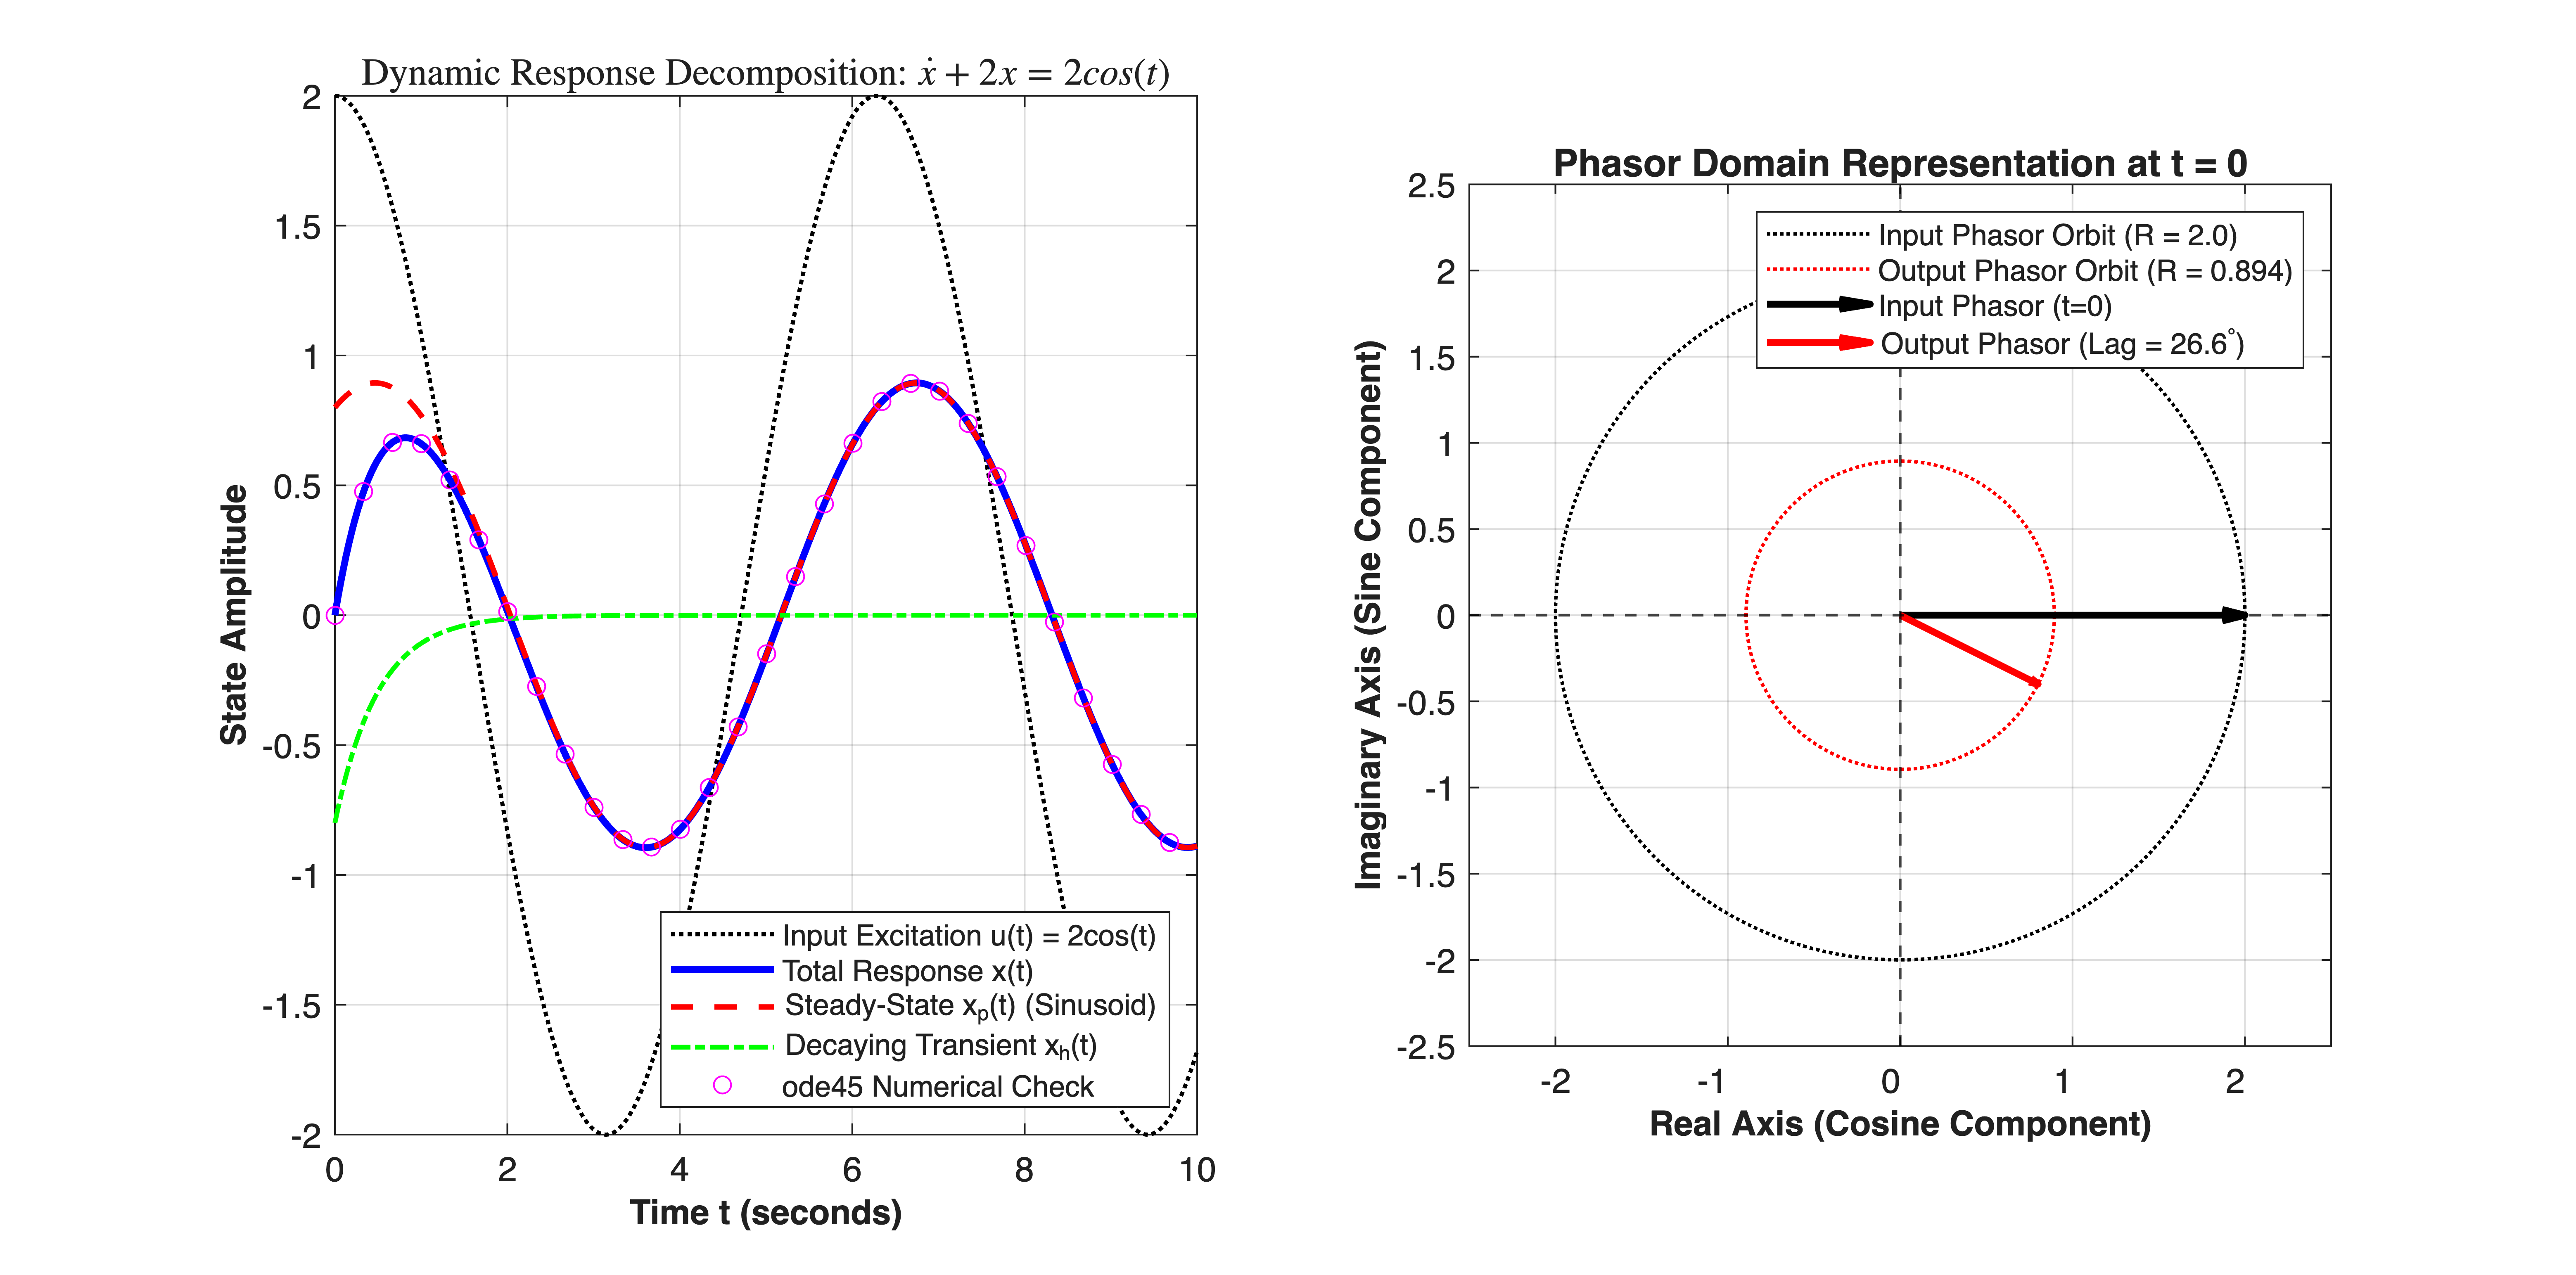

In [1]:
%% MIT 18.03 Lecture 7: Sinusoidal Response & Complex Replacement Method
% Description: Simulates first-order LTI system response to sinusoidal excitation:
%              x' + k*x = F0*cos(omega*t).
%              Deconstructs response into steady-state sinusoidal tracking and
%              exponentially decaying transient using complex replacement (Phasors).
%
% % Required Toolboxes:
% %   - Base MATLAB (Core integration and complex phasor math)
% %   - Control System Toolbox (Optional: for tf and freqresp validation)
%
% % MBD Concept Mapping: Demonstrates continuous frequency response G(j*omega).
% %                      The steady-state amplitude gain is |G(j*omega)| and the
% %                      phase delay is Arg(G(j*omega)), governing sensor filtering
% %                      and harmonic disturbance rejection.


clear; clc; close all;


%% 1. System & Excitation Parameters (From Lecture 7 Section [6])
k = 2.0;               % System pole at s = -2 (Time constant tau = 0.5 s)
F0 = 2.0;              % Input signal amplitude
omega = 1.0;           % Input angular frequency (rad/s)
x0 = 0.0;              % Initial state condition x(0) = 0
t_span = [0, 10];      % Simulation horizon (seconds)


%% 2. Analytical Solution via Complex Replacement (Phasor Method)
% System Transfer Operator: G(s) = 1 / (s + k)
% Frequency Response at excitation frequency: G(j*omega) = 1 / (k + 1i*omega)
G_complex = 1 / (k + 1i * omega);
gain_mag = abs(G_complex);          % Amplitude scaling factor
phase_lag_rad = -angle(G_complex);  % Phase lag: phi = arctan(omega/k)
phase_lag_deg = phase_lag_rad * (180 / pi);


% Complex Steady-State Output Amplitude: Z_p = F0 * G(j*omega)
Z_p = F0 * G_complex; % In lecture: 2 / (2 + 1i) = (4 - 2i)/5
A_out = abs(Z_p);     % Steady-state amplitude: 2 / sqrt(5) ~ 0.8944


% Steady-State Particular Solution: x_p(t) = Re(Z_p * exp(i*omega*t))
% Form: x_p(t) = (4/5)*cos(t) + (2/5)*sin(t) = A_out * cos(omega*t - phi)
x_p_handle = @(t) real(Z_p * exp(1i * omega * t));


% Homogeneous Transient Component: x_h(t) = C * exp(-k*t)
% Initial condition match: x(0) = x_p(0) + C -> C = x0 - real(Z_p)
C_transient = x0 - real(Z_p);
x_h_handle = @(t) C_transient * exp(-k * t);


% Full Analytical Solution
x_total_handle = @(t) x_p_handle(t) + x_h_handle(t);


%% 3. High-Precision Numerical Integration Verification
ode_fun = @(t, x) -k * x + F0 * cos(omega * t);
t_eval = linspace(t_span(1), t_span(2), 600);
opts = odeset('RelTol', 1e-8, 'AbsTol', 1e-10);
[~, x_num] = ode45(ode_fun, t_eval, x0, opts);


%% 4. Figure Generation & Response Breakdown
figure('Color', [1 1 1], 'Position', [100, 100, 1050, 520]);


% Left Subplot: Full Dynamic Response & Steady-State Convergence
subplot(1, 2, 1);
hold on; grid on; box on;


plot(t_eval, F0 * cos(omega * t_eval), 'k:', 'LineWidth', 1.2, ...
     'DisplayName', 'Input Excitation u(t) = 2cos(t)');
plot(t_eval, x_total_handle(t_eval), 'b-', 'LineWidth', 2.0, ...
     'DisplayName', 'Total Response x(t)');
plot(t_eval, x_p_handle(t_eval), 'r--', 'LineWidth', 1.6, ...
     'DisplayName', 'Steady-State x_p(t) (Sinusoid)');
plot(t_eval, x_h_handle(t_eval), 'g-.', 'LineWidth', 1.4, ...
     'DisplayName', 'Decaying Transient x_h(t)');
plot(t_eval(1:20:end), x_num(1:20:end), 'mo', 'MarkerSize', 5, ...
     'DisplayName', 'ode45 Numerical Check');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Amplitude', 'FontSize', 10, 'FontWeight', 'bold');
title("Dynamic Response Decomposition: $\dot{x} + 2x = 2cos(t)$", ...
      'FontSize', 11, 'FontWeight', 'bold', 'Interpreter','latex');
legend('Location', 'southeast', 'FontSize', 8.5);
xlim([0, 10]);


% Right Subplot: Phasor Complex Plane Representation (Input vs Output)
subplot(1, 2, 2);
hold on; grid on; box on;
xline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');


% Plot circular locus of rotating phasors
theta_circle = linspace(0, 2*pi, 200);
plot(F0 * cos(theta_circle), F0 * sin(theta_circle), 'k:', 'LineWidth', 1.0, ...
     'DisplayName', sprintf('Input Phasor Orbit (R = %.1f)', F0));
plot(A_out * cos(theta_circle), A_out * sin(theta_circle), 'r:', 'LineWidth', 1.0, ...
     'DisplayName', sprintf('Output Phasor Orbit (R = %.3f)', A_out));


% Snapshots of phasors at t = 0
quiver(0, 0, F0, 0, 0, 'k-', 'LineWidth', 2.0, 'DisplayName', 'Input Phasor (t=0)');
quiver(0, 0, real(Z_p), imag(Z_p), 0, 'r-', 'LineWidth', 2.0, ...
     'DisplayName', sprintf('Output Phasor (Lag = %.1f^\\circ)', phase_lag_deg));


axis equal;
xlim([-2.5, 2.5]);
ylim([-2.5, 2.5]);
xlabel('Real Axis (Cosine Component)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Imaginary Axis (Sine Component)', 'FontSize', 10, 'FontWeight', 'bold');
title('Phasor Domain Representation at t = 0', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);

In [2]:


fprintf('=== Complex Replacement Method Diagnostics ===\n');

=== Complex Replacement Method Diagnostics ===

In [3]:
fprintf('Complex Output Phasor Z_p: %.4f %+.4fi (Analytic: 4/5 - 2/5i)\n', real(Z_p), imag(Z_p));

Complex Output Phasor Z_p: 0.8000 -0.4000i (Analytic: 4/5 - 2/5i)

In [4]:
fprintf('Steady-State Gain |G(jw)| : %.4f (Attenuation: %.2f dB)\n', gain_mag, 20*log10(gain_mag));

Steady-State Gain |G(jw)| : 0.4472 (Attenuation: -6.99 dB)

In [5]:
fprintf('Steady-State Phase Lag   : %.4f rad (%.2f degrees)\n', phase_lag_rad, phase_lag_deg);

Steady-State Phase Lag   : 0.4636 rad (26.57 degrees)

In [6]:
fprintf('Transient Constant C     : %.4f (Decay rate: -%.1f rad/s)\n', C_transient, k);

Transient Constant C     : -0.8000 (Decay rate: -2.0 rad/s)

In [7]:
fprintf('==============================================\n');